# A two-state hidden Markov model of daily crypto returns

This notebook documents the hidden Markov model behind the regime panel on CryptoQuantLab's Risk tab: the model and its likelihood, how it is fitted and checked, how many states a year of returns supports, how well a year identifies the parameters, and whether the state says anything about the next day using only data available at the time.

The model is in [`batch/cql_batch/hmm.py`](../../batch/cql_batch/hmm.py). Unlike the other models it is fitted in Python, by the nightly `fit-regimes` job, so its tests in [`batch/tests/test_hmm.py`](../../batch/tests/test_hmm.py) compare it with independent libraries rather than with a reference written here.

**The main result is mixed.** The model gives a better one-day distribution than a normal with constant or EWMA variance, but it does not predict the size of the next move better than a simple volatility percentile. That is why it sits beside the threshold badge on the site rather than replacing it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from arch import arch_model

sys.path.insert(0, str(Path.cwd().parent.parent / "batch"))
from cql_batch import hmm

plt.rcParams.update({"figure.figsize": (9, 3.4), "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:.6g}")

def load(coin):
    frame = pd.read_csv(f"../data/{coin}_usd_daily.csv", parse_dates=["date"])
    return frame["date"].iloc[1:].reset_index(drop=True), np.diff(np.log(frame["price_usd"].to_numpy()))

dates, r = load("bitcoin")
n = len(r)
print(f"{n} daily log returns, {dates.iloc[0]:%Y-%m-%d} to {dates.iloc[-1]:%Y-%m-%d}")

363 daily log returns, 2025-10-24 to 2026-10-21


## 1. Why states

Daily returns barely correlate with their own past, but their size does. The squared returns below are autocorrelated at lag 1, so quiet and violent days cluster. GARCH models that with a variance that moves continuously. A hidden Markov model asks instead whether the data looks like a few discrete conditions with switches between them.

In [2]:
series = pd.Series(r)
pd.DataFrame(
    {"returns": [series.autocorr(k) for k in (1, 2, 5)], "squared returns": [(series**2).autocorr(k) for k in (1, 2, 5)]},
    index=pd.Index([1, 2, 5], name="lag"),
)

,returns,squared returns
lag,,
1,-0.0178502,0.352027
2,0.0412148,0.0646797
5,0.0609224,0.10601


\
## 2. The model

Each day has a hidden state $S_t \in \{1, \dots, k\}$ following a Markov chain with transition matrix \
$A = (a_{ij})$, and the log return is normal given the state:

$$r_t \mid S_t = j \sim N(\mu_j, \sigma_j^2), \qquad P(S_{t+1} = j \mid S_t = i) = a_{ij}.$$

The likelihood sums over every path of states, which the forward recursion computes in $O(nk^2)$ rather than $O(k^n)$. \
With $b_j(r) = N(r; \mu_j, \sigma_j^2)$:

$$\alpha_t(j) = \frac{b_j(r_t) \sum_i \alpha_{t-1}(i)\, a_{ij}}{c_t}, \qquad \log L = \sum_{t=1}^{n} \log c_t.$$

$\alpha_t$ is the **filtered** probability $P(S_t \mid r_1, \dots, r_t)$. The backward recursion adds the later data to \
give the **smoothed** probability $P(S_t \mid r_1, \dots, r_n)$.

The parameters are fitted by expectation-maximization (Baum-Welch). The E step computes the smoothed probabilities \
$\gamma_t(j)$ and expected transitions $\xi_t(i,j)$. The M step is closed-form:

$$\hat a_{ij} = \frac{\sum_t \xi_t(i,j)}{\sum_t \gamma_t(i)}, \quad \hat\mu_j = \frac{\sum_t \gamma_t(j)\, r_t}{\sum_t \gamma_t(j)}, \quad \hat\sigma_j^2 = \frac{\sum_t \gamma_t(j)(r_t - \hat\mu_j)^2}{\sum_t \gamma_t(j)}.$$

A normal likelihood is unbounded as a state's variance shrinks onto a few similar returns, so each variance is floored \
at $10^{-3}$ of the sample variance. EM runs from ten starts and keeps the highest likelihood. States are numbered by \
variance, so the labels stay comparable between refits.

## 3. Fit to Bitcoin

In [3]:
fit = hmm.fit_hmm(r)
pd.DataFrame(
    {
        "daily mean": fit.means,
        "daily volatility": np.sqrt(fit.variances),
        "annualized volatility": np.sqrt(fit.variances * 365.25),
        "stay probability": np.diag(fit.transition),
        "expected days": hmm.expected_duration(fit.transition),
        "long-run share": hmm.stationary_distribution(fit.transition),
    },
    index=pd.Index(["calm", "turbulent"], name="state"),
).T

state,calm,turbulent
daily mean,-0.000598881,-0.00129495
daily volatility,0.0159694,0.0431735
annualized volatility,0.305199,0.82511
stay probability,0.934714,0.681241
expected days,15.3173,3.13717
long-run share,0.830005,0.169995


The states differ in volatility by a factor of about 2.7. The calm state is the persistent one, with spells of about 15 days. The turbulent state lasts about 3 days, so it behaves more like a cluster of bad days than a long market phase.

Both daily means are small and negative, and section 6 shows they can't be told apart. **The states describe volatility, not direction.**

### Checks

The tests in `batch/tests/test_hmm.py` run these on Bitcoin and Ethereum, and also confirm that the recursions match enumerating all $3^8$ paths of a short series to 1e-12 and that EM iterates match hmmlearn to 1e-9. The cell below repeats the comparison with statsmodels, which maximizes the likelihood directly rather than by EM.

In [4]:
model = sm.tsa.MarkovRegression(r, k_regimes=2, trend="c", switching_variance=True)
model.initialize_steady_state()

params = np.r_[fit.transition[0, 0], fit.transition[1, 0], fit.means, fit.variances]
stationary = hmm.stationary_distribution(fit.transition)
ours = hmm.forward_backward(hmm.log_densities(r, fit.means, fit.variances), stationary, fit.transition)[0]
theirs = model.loglike(params)
restarts = model.fit(search_reps=40, search_iter=20, disp=False)

print(f"same parameters, stationary start: ours {ours:.8f}, statsmodels {theirs:.8f}")
print(f"best statsmodels fit from 40 random starts: {restarts.llf:.6f}")
print(f"our fit, which also estimates the initial state: {fit.log_likelihood:.6f}")

same parameters, stationary start: ours 890.69944247, statsmodels 890.69944247
best statsmodels fit from 40 random starts: 890.700918
our fit, which also estimates the initial state: 890.793486


The two likelihood functions agree at the same parameters. statsmodels ties the initial state to the stationary distribution while this model estimates it, which accounts for the small difference between the two maxima. statsmodels' random restarts find nothing higher.

## 4. Filtered and smoothed probabilities

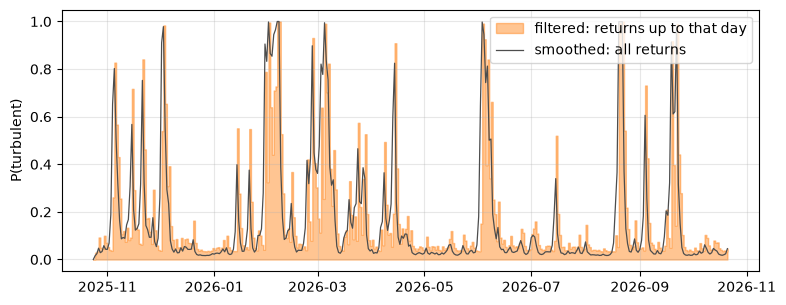

days above 50%: filtered 37, smoothed 40
correlation between the two: 0.913


In [5]:
fig, ax = plt.subplots()
ax.fill_between(dates, fit.filtered[:, 1], step="post", alpha=0.45, color="tab:orange", label="filtered: returns up to that day")
ax.plot(dates, fit.smoothed[:, 1], color="0.3", lw=0.9, label="smoothed: all returns")
ax.set_ylabel("P(turbulent)")
ax.legend(loc="upper right")
plt.show()

print(f"days above 50%: filtered {(fit.filtered[:, 1] > 0.5).sum()}, smoothed {(fit.smoothed[:, 1] > 0.5).sum()}")
print(f"correlation between the two: {np.corrcoef(fit.filtered[:, 1], fit.smoothed[:, 1])[0, 1]:.3f}")

The smoothed line is sharper because it uses later returns, so it could not have been known on the day. The filtered area doesn't use later returns, but the parameters behind it come from the whole year, so the history on the site is **not** a true out-of-sample record. Section 7 is the out-of-sample test.

## 5. How many states

In [6]:
log_likelihood_1 = -0.5 * n * (np.log(2 * np.pi * r.var()) + 1)
fit_3 = hmm.fit_hmm(r, k=3)
display(pd.DataFrame(
    {
        "parameters": [2, fit.parameter_count, fit_3.parameter_count],
        "log-likelihood": [log_likelihood_1, fit.log_likelihood, fit_3.log_likelihood],
        "AIC": [4 - 2 * log_likelihood_1, fit.aic(), fit_3.aic()],
        "BIC": [2 * np.log(n) - 2 * log_likelihood_1, fit.bic(n), fit_3.bic(n)],
    },
    index=pd.Index([1, 2, 3], name="states"),
))

cross_section = pd.read_csv("../data/hmm_cross_section.csv")
cross_section.best_bic_states.value_counts().sort_index().rename("coins preferring this many states, by BIC").to_frame()

,parameters,log-likelihood,AIC,BIC
states,,,,
1,2,854.764,-1705.53,-1697.74
2,7,890.793,-1767.59,-1740.33
3,14,898.385,-1768.77,-1714.25


,"coins preferring this many states, by BIC"
best_bic_states,
1,5
2,79
3,18


BIC clearly prefers two states on Bitcoin. AIC barely separates two from three, and its small preference for three is not worth doubling the parameters on 363 returns. The third state's volatility of about 0.3% a day also looks like it is fitting a few unusually quiet days rather than a market condition.

The cross-section comes from [`scripts/hmm_cross_section.py`](../scripts/hmm_cross_section.py), run on a year of every stored coin. Two states wins for most coins, so the site fixes two. Where two states don't beat one normal by BIC, the site says so and shows no state.

## 6. What a year of data can identify

The cell below simulates 300 years from the fitted Bitcoin model and refits each one.

In [7]:
rng = np.random.default_rng(7)
sds = np.sqrt(fit.variances)
stationary = hmm.stationary_distribution(fit.transition)

def simulate():
    states = np.empty(n, dtype=int)
    states[0] = rng.choice(2, p=stationary)
    for t in range(1, n):
        states[t] = rng.choice(2, p=fit.transition[states[t - 1]])
    return fit.means[states] + sds[states] * rng.standard_normal(n), states

rows = []
for _ in range(300):
    x, states = simulate()
    g = hmm.fit_hmm(x, starts=3)
    one_state = 2 * np.log(n) + n * (np.log(2 * np.pi * x.var()) + 1)
    rows.append({
        "calm stay": g.transition[0, 0], "turbulent stay": g.transition[1, 1],
        "calm daily vol": np.sqrt(g.variances[0]), "turbulent daily vol": np.sqrt(g.variances[1]),
        "calm mean": g.means[0], "turbulent mean": g.means[1],
        "supported": g.bic(n) < one_state, "accuracy": (g.smoothed.argmax(axis=1) == states).mean(),
    })
sims = pd.DataFrame(rows)

truth = pd.Series({
    "calm stay": fit.transition[0, 0], "turbulent stay": fit.transition[1, 1],
    "calm daily vol": sds[0], "turbulent daily vol": sds[1],
    "calm mean": fit.means[0], "turbulent mean": fit.means[1],
})
display(pd.DataFrame({
    "true": truth, "mean estimate": sims[truth.index].mean(), "std dev": sims[truth.index].std(),
    "5%": sims[truth.index].quantile(0.05), "95%": sims[truth.index].quantile(0.95),
}))
print(f"BIC prefers two states in {sims.supported.mean():.0%} of simulations; smoothed state correct on {sims.accuracy.mean():.0%} of days")

,true,mean estimate,std dev,5%,95%
calm stay,0.934714,0.928134,0.0377866,0.861814,0.973149
turbulent stay,0.681241,0.667208,0.144314,0.382341,0.850285
calm daily vol,0.0159694,0.0157953,0.00097953,0.0141325,0.0175022
turbulent daily vol,0.0431735,0.0423507,0.00592184,0.033202,0.0524303
calm mean,-0.000598881,-0.000542979,0.00108297,-0.00217349,0.00133035
turbulent mean,-0.00129495,-0.00154891,0.00695467,-0.0128487,0.00881647


BIC prefers two states in 97% of simulations; smoothed state correct on 89% of days


Three things follow, even though the simulated data really does come from this model:

- **Volatilities are well identified.** Each state's volatility is estimated to within about 6–14%.
- **The turbulent state's persistence is not.** The 90% range for its stay probability is roughly 0.4 to 0.85, which is an expected spell of under 2 days or nearly 7. The site's "lasts about 3 days" is rough.
- **The means can't be separated.** The turbulent mean's standard error is about five times the estimate itself, so nothing here supports reading the states as bull and bear.

## 7. Does the state say anything about the next day?

This is the test that decided how the model is used. For Bitcoin and Ethereum, each model is refitted weekly on the previous 180 returns and scored on each following day, using only data available at the time. The score is the mean log density of the realized return under the one-day forecast, so higher is better.

GARCH is the natural rival, so it joins here using `arch`, with parameters frozen between refits in the same way.

In [8]:
TRAIN, REFIT = 180, 7

def log_normal(x, mean, variance):
    return -0.5 * (np.log(2 * np.pi * variance) + (x - mean) ** 2 / variance)

def garch_step(history, params):
    mu, omega, alpha, beta = params
    variance = history.var()
    for x in history:
        variance = omega + alpha * (x - mu) ** 2 + beta * variance
    return mu, variance

def walk_forward(x):
    rows = []
    for t in range(TRAIN, len(x)):
        history = x[t - TRAIN : t]
        if (t - TRAIN) % REFIT == 0:
            fitted = hmm.fit_hmm(history, starts=5)
            result = arch_model(history * 100, mean="Constant", vol="GARCH", p=1, q=1).fit(disp="off")
            garch_params = result.params["mu"] / 100, result.params["omega"] / 1e4, result.params["alpha[1]"], result.params["beta[1]"]

        _, filtered, _, _ = hmm.forward_backward(hmm.log_densities(history, fitted.means, fitted.variances), fitted.initial, fitted.transition)
        predicted = filtered[-1] @ fitted.transition
        weights = 0.94 ** np.arange(TRAIN - 1, -1, -1)
        mu, garch_variance = garch_step(history, garch_params)

        rows.append({
            "hidden Markov": np.logaddexp.reduce(log_normal(x[t], fitted.means, fitted.variances) + np.log(predicted + 1e-300)),
            "constant normal": log_normal(x[t], history.mean(), history.var(ddof=1)),
            "EWMA normal": log_normal(x[t], 0.0, (weights * history**2).sum() / weights.sum()),
            "GARCH normal": log_normal(x[t], mu, garch_variance),
        })
    return pd.DataFrame(rows)

scores = {coin: walk_forward(load(coin)[1]) for coin in ["bitcoin", "ethereum"]}
pd.DataFrame({coin: frame.mean() for coin, frame in scores.items()}).rename_axis("mean log score")

,bitcoin,ethereum
mean log score,,
hidden Markov,2.5755,2.26376
constant normal,2.48675,2.16786
EWMA normal,2.5052,2.03235
GARCH normal,2.51701,2.12327


On both coins the hidden Markov model scores above GARCH with normal innovations as well as the two simpler rivals. That is two coins and about 180 days each, and a normal GARCH has thin tails, so it isn't evidence against GARCH in general. The next table asks the same question across every coin, without GARCH, along with whether the state predicts the size of the next move.

In [9]:
walk = cross_section[cross_section.test_days.notna()]

def summarize(frame):
    turbulent = frame[frame.turbulent_days >= 5]
    return {
        "coins": len(frame),
        "better than constant normal": int((frame.hmm_score > frame.normal_score).sum()),
        "better than EWMA normal": int((frame.hmm_score > frame.ewma_score).sum()),
        "next-day move, turbulent / calm (median)": (turbulent.move_after_turbulent / turbulent.move_after_calm).median(),
        "next-day move, high / low percentile (median)": (frame.move_after_high_percentile / frame.move_after_low_percentile).median(),
        "correlation with next move, hidden Markov (median)": frame.hmm_move_correlation.median(),
        "correlation with next move, percentile (median)": frame.percentile_move_correlation.median(),
    }

pd.DataFrame({
    "every coin": summarize(walk),
    "daily volatility of at least 0.5%": summarize(walk[walk.daily_volatility >= 0.005]),
})

,every coin,daily volatility of at least 0.5%
coins,99,82
better than constant normal,94,77
better than EWMA normal,82,69
"next-day move, turbulent / calm (median)",1.48494,1.46963
"next-day move, high / low percentile (median)",1.43501,1.43022
"correlation with next move, hidden Markov (median)",0.110874,0.110829
"correlation with next move, percentile (median)",0.157483,0.159835


Removing stablecoins and tokenized funds, the second column, changes little.

- **As a distribution, the model does better.** It beats a normal with constant or EWMA variance for most coins. A two-state mixture has fat tails, which a single normal lacks, so at least part of this advantage is simply a better tail shape rather than knowing the state.
- **As a predictor of move size, it adds nothing over a percentile.** The next day's move is about 1.47 times larger after a turbulent day, against 1.43 times after a high-percentile day, and the percentile correlates more strongly with the size of the next move.

So the threshold badge stays as the headline, because it is simpler and at least as predictive. The hidden Markov panel adds what the threshold can't give: a probability, a day-by-day state and the speed of switching.

## 8. Limitations

- **Normal within each state.** Fat tails come only from the mixture, so a large move is read as a state switch even when it is a one-off. A Student-t emission is the obvious extension.
- **Constant duration.** Time in a state is geometric, so the chance of leaving doesn't depend on how long the state has lasted.
- **A year of data.** Section 6 shows what that leaves uncertain. The history grows by a day each night.
- **Stored history isn't out of sample.** The chart uses this year's parameters. Each night's row is kept, so a true out-of-sample record is building up from the first run.
- **Walk-forward sample.** About 180 test days, overlapping across coins that move together, so these counts are descriptive rather than a formal test.

## References

- Baum, L. E., Petrie, T., Soules, G. and Weiss, N. (1970). A maximization technique occurring in the statistical analysis of probabilistic functions of Markov chains. *Annals of Mathematical Statistics*, 41(1), 164–171.
- Dempster, A. P., Laird, N. M. and Rubin, D. B. (1977). Maximum likelihood from incomplete data via the EM algorithm. *Journal of the Royal Statistical Society B*, 39(1), 1–38.
- Hamilton, J. D. (1989). A new approach to the economic analysis of nonstationary time series and the business cycle. *Econometrica*, 57(2), 357–384.
- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257–286.
- Schwarz, G. (1978). Estimating the dimension of a model. *Annals of Statistics*, 6(2), 461–464.